# GASTON and MorphoGAM on noise: kidney shape

Both datasets have 1000 spots on the kidney and 200 genes. No gene shares a spatial trend with any other gene, and none follows a common axis.

1. **Part A, independent noise:** $Y_{ig} \sim \text{Poisson}(5)$, independent across spots and genes.
2. **Part B, locally blurred noise:** $Y_{ig} \sim \text{Poisson}(\lambda_{ig})$ with $\log \lambda_{ig} = \log 5 + \sigma Z'_{ig}$ (recentered). Here $Z'_g$ is white noise smoothed with a Gaussian of bandwidth **15 µm**, independently for each gene. Each gene is short-range autocorrelated, but there is still no shared gradient.

We run each method as its authors do and count the genes it calls significant along the 1-D coordinate it learns:

- **GASTON (native):** GLM-PCA, then a neural-net isodepth trained with restarts, then a Poisson fit of each gene along the isodepth with one domain. A gene's slope is set to nonzero when its likelihood-ratio p-value is below `t = 0.1`.
- **MorphoGAM:** `CurveFinder` estimates a curve through the spots and gives each spot a coordinate `t` along it. A negative-binomial GAM `y ~ s(t)` is then fit to each gene, and the `mgcv` p-value `pv.t` is reported.

The kidney is the region of $[-3,3]^2$ where $\sqrt{x^2+y^2} \le 1 - 2\sin\theta + \cos(\theta^2)$, with $\theta = \operatorname{atan2}(y, x)$. Spots are drawn uniformly inside it. The repo stores shapes in $[0,1]^2$; for the blur, that unit square is **960 µm** wide, which matches `configs/synthetic/kernel_blurred_per_gene_sigma_unif.json`.

In [1]:
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from glmpca import glmpca
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", message=".*weights_only.*")
REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO_ROOT))

from data.schemas import DataConfig
from data.synthetic import generate_synthetic_dataset
from gaston import dp_related, neural_net, process_NN_output, segmented_fit

OUT_DIR = REPO_ROOT / "notebooks" / "kidney_noise_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
RSCRIPT = "/home/jhu/ajain71/miniforge3/envs/r_env/bin/Rscript"
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [2]:
# ---- Configuration ----
SEED = 0
N_SPOTS = 1000
N_GENES = 200
MEAN_COUNT = 5.0

# Part B blur (log-rate noise smoothed with a Gaussian kernel)
TISSUE_WIDTH_UM = 960.0   # width of the [0, 1]^2 shape box in microns
BLUR_SIGMA_UM = 15.0      # Gaussian bandwidth
BLUR_AMPLITUDE = 0.5      # sigma on the log-rate noise before smoothing

# GASTON (cerebellum tutorial defaults)
GLMPCA_DIMS = 5
GLMPCA_PENALTY = 10
GLMPCA_ITERS = 30
ISODEPTH_ARCH = [20, 20]
EXPRESSION_ARCH = [20, 20]
NUM_EPOCHS = 10000
NUM_RESTARTS = 30
GASTON_T = 0.1            # native slope threshold: slope kept if LLR p < t

# MorphoGAM
MORPHOGAM_KNN = 5

ALPHA = 0.05
N_SHOW = 6
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu" and NUM_EPOCHS * NUM_RESTARTS > 50_000:
    print("WARNING: no GPU found; full GASTON training on CPU will be slow.")
gene_names = np.array([f"gene_{g:03d}" for g in range(N_GENES)])

## Analysis functions (shared by Parts A and B)

In [3]:
def simulate(**extra):
    ds = generate_synthetic_dataset(DataConfig(
        source="synthetic", mode="noise", shape="kidney", n_cells=N_SPOTS, n_genes=N_GENES,
        expression_distribution="poisson", mean_count=MEAN_COUNT,
        sampling_bias={"type": "uniform"}, seed=SEED, **extra,
    ))
    counts = np.asarray(ds.A, dtype=np.float64)
    coords = 6.0 * np.asarray(ds.S, dtype=np.float64) - 3.0   # native [-3, 3] units
    return counts, coords


def nn_correlation(counts, coords):
    _, idx = cKDTree(coords).query(coords, k=2)
    nn = idx[:, 1]
    return float(np.nanmean([np.corrcoef(counts[:, g], counts[nn, g])[0, 1] for g in range(counts.shape[1])]))


def plot_dataset(counts, coords, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    axes[0].scatter(coords[:, 0], coords[:, 1], s=6, c="k"); axes[0].set_title(f"{title}: {len(coords)} spots")
    for ax, g in zip(axes[1:], [0, 1]):
        sc = ax.scatter(coords[:, 0], coords[:, 1], s=6, c=counts[:, g], cmap="viridis")
        ax.set_title(gene_names[g]); plt.colorbar(sc, ax=ax)
    for ax in axes:
        ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
    plt.tight_layout(); plt.show()
    print(f"count mean {counts.mean():.3f}, var {counts.var():.3f}, "
          f"mean nearest-neighbor correlation {nn_correlation(counts, coords):.3f}")


def run_gaston(counts, coords, run_dir):
    glmpca_res = glmpca.glmpca(
        counts.T, GLMPCA_DIMS, fam="poi", penalty=GLMPCA_PENALTY,
        ctl={"maxIter": GLMPCA_ITERS, "eps": 1e-4, "optimizeTheta": True},
    )
    S_torch, A_torch = neural_net.load_rescale_input_data(coords, np.asarray(glmpca_res["factors"]))
    for seed in range(NUM_RESTARTS):
        seed_dir = run_dir / f"rep{seed}"
        if (seed_dir / "final_model.pt").exists():
            continue
        seed_dir.mkdir(parents=True, exist_ok=True)
        neural_net.train(
            S_torch, A_torch, S_hidden_list=ISODEPTH_ARCH, A_hidden_list=EXPRESSION_ARCH,
            epochs=NUM_EPOCHS, checkpoint=NUM_EPOCHS, device=DEVICE,
            save_dir=str(seed_dir), optim="adam", seed=seed, save_final=True,
        )
    model, A_best, S_best = process_NN_output.process_files(str(run_dir))
    isodepth, labels = dp_related.get_isodepth_labels(model, A_best, S_best, 1)
    pw = segmented_fit.pw_linear_fit(counts, labels, isodepth, None, [],
                                     umi_threshold=0, t=GASTON_T, zero_fit_threshold=0)
    slope, intercept, _, pv = pw["all_cell_types"]
    res = pd.DataFrame({"gene": gene_names, "slope": slope[:, 0], "intercept": intercept[:, 0], "pval": pv[:, 0]})
    res["padj_bh"] = multipletests(res["pval"], method="fdr_bh")[1]
    res = res.sort_values("pval").reset_index(drop=True)
    print(f"GASTON native SVGs (nonzero slope, p < {GASTON_T}): {(res['slope'] != 0).sum()} / {N_GENES}")
    return isodepth, res


def run_morphogam(counts, coords, run_dir):
    run_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(counts.astype(int), columns=gene_names).to_csv(run_dir / "counts.csv", index=False)
    pd.DataFrame(coords, columns=["x", "y"]).to_csv(run_dir / "coords.csv", index=False)
    proc = subprocess.run([RSCRIPT, str(OUT_DIR / "run_morphogam.R"), str(run_dir), str(MORPHOGAM_KNN)],
                          capture_output=True, text=True)
    if proc.returncode != 0:
        raise RuntimeError(proc.stderr[-4000:])
    xyt = pd.read_csv(run_dir / "morphogam_xyt.csv")
    fxs_t = pd.read_csv(run_dir / "morphogam_fxs_t.csv")
    res = pd.read_csv(run_dir / "morphogam_results.csv")
    res["padj_bh"] = multipletests(res["pv.t"], method="fdr_bh")[1]
    res = res.sort_values("pv.t").reset_index(drop=True)
    print(f"MorphoGAM SVGs (pv.t < {ALPHA}): {(res['pv.t'] < ALPHA).sum()} / {N_GENES}")
    return xyt, fxs_t, res


def plot_coordinates(coords, isodepth, xyt, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    sc = axes[0].scatter(coords[:, 0], coords[:, 1], c=isodepth, s=8, cmap="RdYlBu_r")
    axes[0].set_title("GASTON isodepth"); plt.colorbar(sc, ax=axes[0])
    sc = axes[1].scatter(xyt["x"], xyt["y"], c=xyt["t"], s=8, cmap="RdYlBu_r")
    o = np.argsort(xyt["t"].to_numpy())
    axes[1].plot(xyt["f1"].to_numpy()[o], xyt["f2"].to_numpy()[o], "k-", lw=2, label="fitted curve")
    axes[1].legend(loc="upper right"); axes[1].set_title("MorphoGAM t (along curve)"); plt.colorbar(sc, ax=axes[1])
    sc = axes[2].scatter(xyt["x"], xyt["y"], c=xyt["r"], s=8, cmap="PuOr")
    axes[2].set_title("MorphoGAM r (orthogonal)"); plt.colorbar(sc, ax=axes[2])
    for ax in axes:
        ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def svg_summary(gaston, morpho, label):
    rows = [
        ("GASTON", "native: LLR p < %.2f" % GASTON_T, int((gaston["slope"] != 0).sum()), GASTON_T * N_GENES),
        ("GASTON", "p < %.2f" % ALPHA, int((gaston["pval"] < ALPHA).sum()), ALPHA * N_GENES),
        ("GASTON", "BH q < %.2f" % ALPHA, int((gaston["padj_bh"] < ALPHA).sum()), 0.0),
        ("MorphoGAM", "pv.t < %.2f" % ALPHA, int((morpho["pv.t"] < ALPHA).sum()), ALPHA * N_GENES),
        ("MorphoGAM", "BH q < %.2f" % ALPHA, int((morpho["padj_bh"] < ALPHA).sum()), 0.0),
    ]
    df = pd.DataFrame(rows, columns=["method", "rule", "n_svgs", "expected_if_calibrated"])
    df.insert(0, "dataset", label)
    df["true_svgs"] = 0
    return df


def plot_summary(summary, gaston, morpho, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    x = np.arange(len(summary))
    axes[0].bar(x, summary["n_svgs"], color=["C0", "C0", "C0", "C1", "C1"], label="called")
    axes[0].scatter(x, summary["expected_if_calibrated"], c="k", marker="_", s=400, zorder=3, label="expected by chance")
    axes[0].set_xticks(x); axes[0].set_xticklabels([f"{m}\n{r}" for m, r in zip(summary["method"], summary["rule"])], fontsize=8)
    axes[0].set_ylabel(f"SVGs called (of {N_GENES})"); axes[0].legend(fontsize=8); axes[0].set_title("Genes called significant (truth = 0)")
    bins = np.linspace(0, 1, 21)
    axes[1].hist(gaston["pval"], bins=bins, alpha=0.6, label="GASTON LLR p")
    axes[1].hist(morpho["pv.t"], bins=bins, alpha=0.6, label="MorphoGAM pv.t")
    axes[1].axhline(N_GENES / 20, color="k", ls="--", label="uniform (calibrated)")
    axes[1].set_xlabel("p-value"); axes[1].set_ylabel("genes"); axes[1].legend(); axes[1].set_title("p-value histograms")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_top_genes(counts, coords, axis_vals, genes, title, fitted):
    exposure = counts.sum(axis=1)
    norm_expr = counts / exposure[:, None] * np.median(exposure)
    gi = {g: i for i, g in enumerate(gene_names)}
    fig, axes = plt.subplots(2, len(genes), figsize=(3.0 * len(genes), 6))
    edges = np.quantile(axis_vals, np.linspace(0, 1, 16))
    mids = 0.5 * (edges[:-1] + edges[1:])
    which = np.clip(np.digitize(axis_vals, edges[1:-1]), 0, len(mids) - 1)
    o = np.argsort(axis_vals)
    for k, g in enumerate(genes):
        y = norm_expr[:, gi[g]]
        ax = axes[0, k]
        ax.scatter(axis_vals, y, s=3, alpha=0.25, c="gray")
        ax.plot(mids, [y[which == b].mean() for b in range(len(mids))], "o-", c="C3", ms=3, label="binned mean")
        ax.plot(axis_vals[o], fitted(g)[o], "k-", lw=1.5, label="method fit")
        ax.set_title(g, fontsize=9)
        if k == 0:
            ax.legend(fontsize=7)
        axes[1, k].scatter(coords[:, 0], coords[:, 1], c=y, s=4, cmap="viridis")
        axes[1, k].set_aspect("equal"); axes[1, k].set_xticks([]); axes[1, k].set_yticks([])
    fig.suptitle(title); plt.tight_layout(); plt.show()


def show_top_genes(counts, coords, isodepth, gaston, xyt, fxs_t, morpho, label):
    med = np.median(counts.sum(axis=1))
    g_rows = gaston.set_index("gene")
    gaston_fit = lambda g: med * np.exp(g_rows.loc[g, "slope"] * isodepth + g_rows.loc[g, "intercept"])
    plot_top_genes(counts, coords, isodepth, gaston["gene"].head(N_SHOW).tolist(),
                   f"{label} | GASTON: top genes by LLR p-value vs isodepth", gaston_fit)
    display(gaston.head(N_SHOW))
    m_rows = morpho.set_index("gene")
    morpho_fit = lambda g: med * np.exp(m_rows.loc[g, "intercept"] + fxs_t[g].to_numpy())
    plot_top_genes(counts, coords, xyt["t"].to_numpy(), morpho["gene"].head(N_SHOW).tolist(),
                   f"{label} | MorphoGAM: top genes by pv.t vs t", morpho_fit)
    display(morpho[["gene", "pv.t", "padj_bh", "peak.t", "range.t"]].head(N_SHOW))


def overlap(gaston, morpho):
    set_g = set(gaston.loc[gaston["slope"] != 0, "gene"])
    set_m = set(morpho.loc[morpho["pv.t"] < ALPHA, "gene"])
    print(f"GASTON native SVGs: {len(set_g)} | MorphoGAM SVGs: {len(set_m)}")
    print(f"Called by both: {len(set_g & set_m)} -> {sorted(set_g & set_m)}")
    print(f"Expected overlap if independent: {len(set_g) * len(set_m) / N_GENES:.1f}")

# Part A: independent Poisson(5) noise

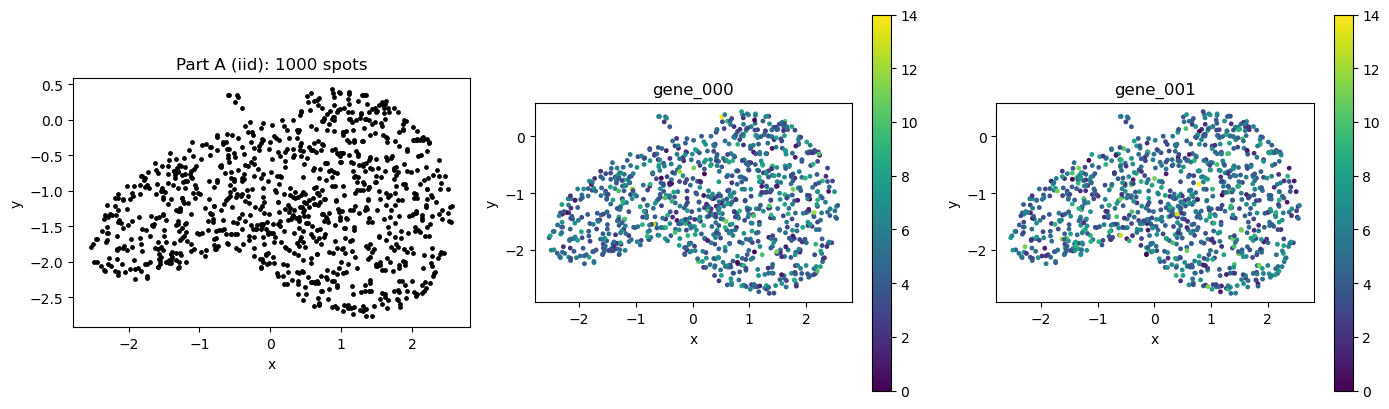

count mean 5.004, var 5.006, mean nearest-neighbor correlation -0.004


In [4]:
counts_a, coords_a = simulate(sigma=0.0)
plot_dataset(counts_a, coords_a, "Part A (iid)")

## A.1 GASTON and MorphoGAM

In [5]:
iso_a, gaston_a = run_gaston(counts_a, coords_a, OUT_DIR / "gaston_runs")
xyt_a, fxs_a, morpho_a = run_morphogam(counts_a, coords_a, OUT_DIR / "morphogam_iid")


best model: /weka/scratch/jhu/uchitra1/users/ajain71/isodepth-statistical-testing/notebooks/kidney_noise_outputs/gaston_runs/rep26
Poisson regression for ALL cell types


GASTON native SVGs (nonzero slope, p < 0.1): 20 / 200


MorphoGAM SVGs (pv.t < 0.05): 6 / 200


## A.2 Learned coordinates

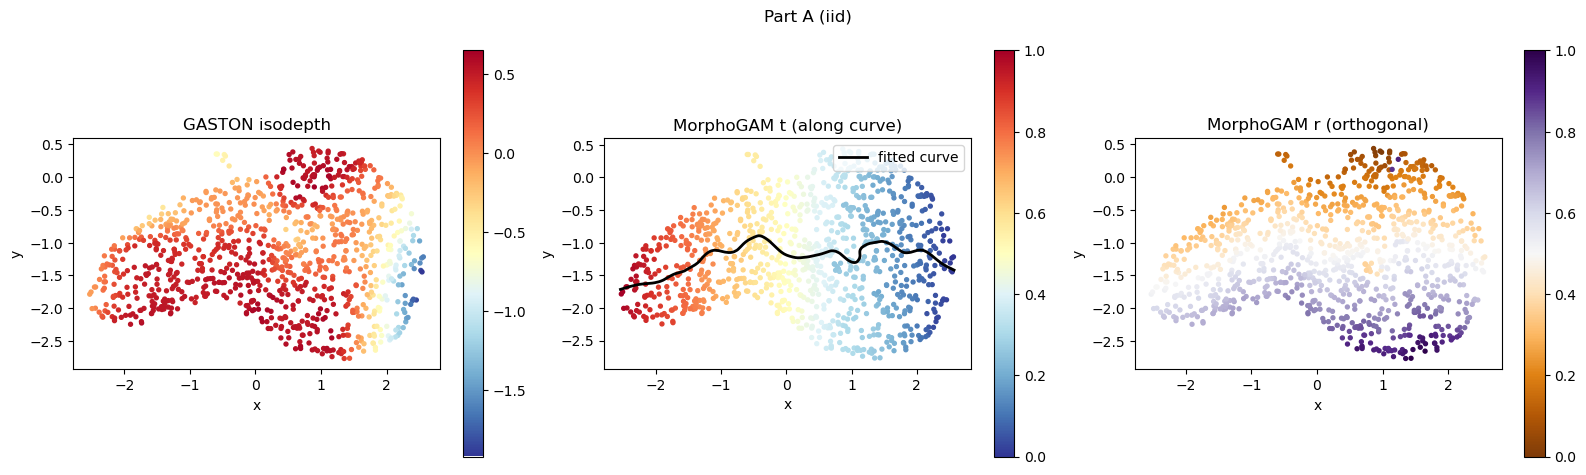

In [6]:
plot_coordinates(coords_a, iso_a, xyt_a, "Part A (iid)")

## A.3 SVG counts

,dataset,method,rule,n_svgs,expected_if_calibrated,true_svgs
0,A: iid Poisson(5),GASTON,native: LLR p < 0.10,20,20.0,0
1,A: iid Poisson(5),GASTON,p < 0.05,15,10.0,0
2,A: iid Poisson(5),GASTON,BH q < 0.05,0,0.0,0
3,A: iid Poisson(5),MorphoGAM,pv.t < 0.05,6,10.0,0
4,A: iid Poisson(5),MorphoGAM,BH q < 0.05,0,0.0,0


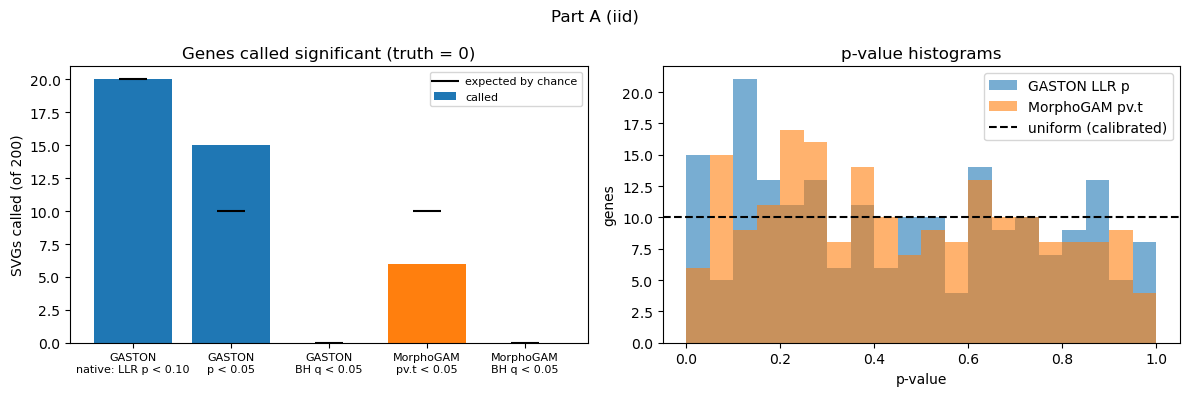

In [7]:
summary_a = svg_summary(gaston_a, morpho_a, "A: iid Poisson(5)")
display(summary_a)
plot_summary(summary_a, gaston_a, morpho_a, "Part A (iid)")

## A.4 Top genes and overlap

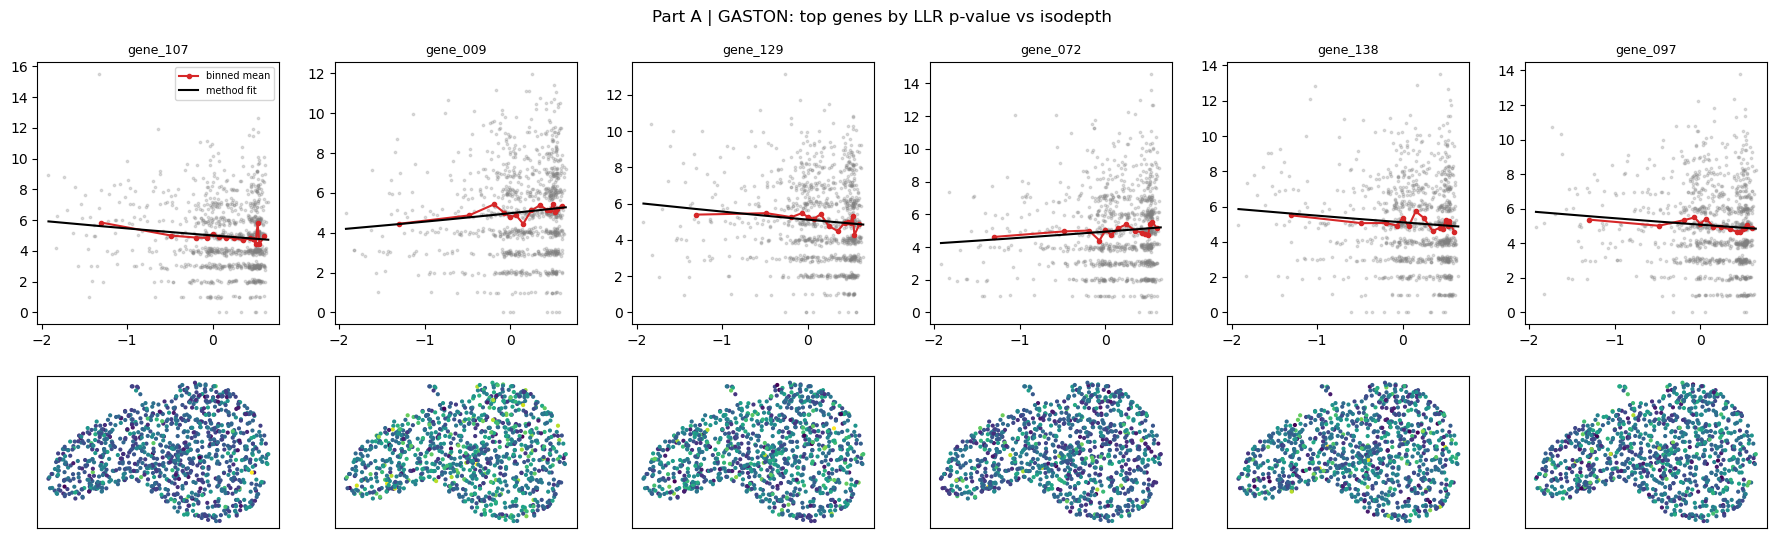

,gene,slope,intercept,pval,padj_bh
0,gene_107,-0.087356,-5.297619,0.003410,0.318904
1,gene_009,0.089178,-5.302705,0.003938,0.318904
2,gene_129,-0.083303,-5.275330,0.004784,0.318904
3,gene_072,0.079171,-5.310554,0.010645,0.532273
4,gene_138,-0.071569,-5.277280,0.015701,0.566882
5,gene_097,-0.070898,-5.282506,0.017006,0.566882


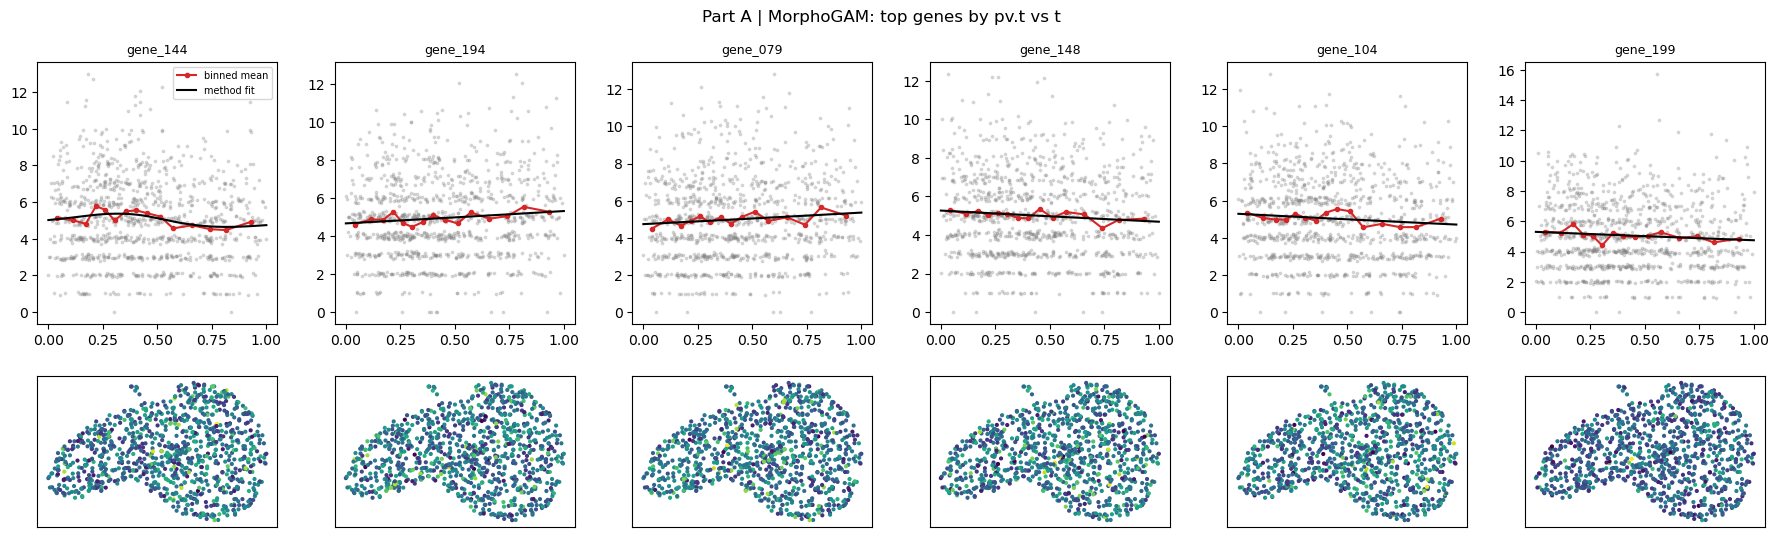

,gene,pv.t,padj_bh,peak.t,range.t
0,gene_144,0.003976,0.795158,0.037429,0.295225
1,gene_194,0.018206,0.798185,0.012485,0.109451
2,gene_079,0.024602,0.798185,0.008887,0.078962
3,gene_148,0.035804,0.798185,0.004342,0.038560
4,gene_104,0.035843,0.798185,0.004318,0.038513
5,gene_199,0.047035,0.798185,0.000807,0.007271


GASTON native SVGs: 20 | MorphoGAM SVGs: 6
Called by both: 1 -> ['gene_079']
Expected overlap if independent: 0.6


In [8]:
show_top_genes(counts_a, coords_a, iso_a, gaston_a, xyt_a, fxs_a, morpho_a, "Part A")
overlap(gaston_a, morpho_a)

# Part B: noise blurred with a 15 µm Gaussian

The log-rate noise for each gene is smoothed independently using the repo's `kernel.type = "smooth"`, with `distance = BLUR_SIGMA_UM` and `data.scale = TISSUE_WIDTH_UM`.
Each gene then has short-range spatial autocorrelation, but the genes share no common gradient or axis. A gene called significant along a learned axis therefore reflects short-range autocorrelation, not real structure along that axis.

median nearest-spot spacing: 7.5 um; blur bandwidth: 15.0 um


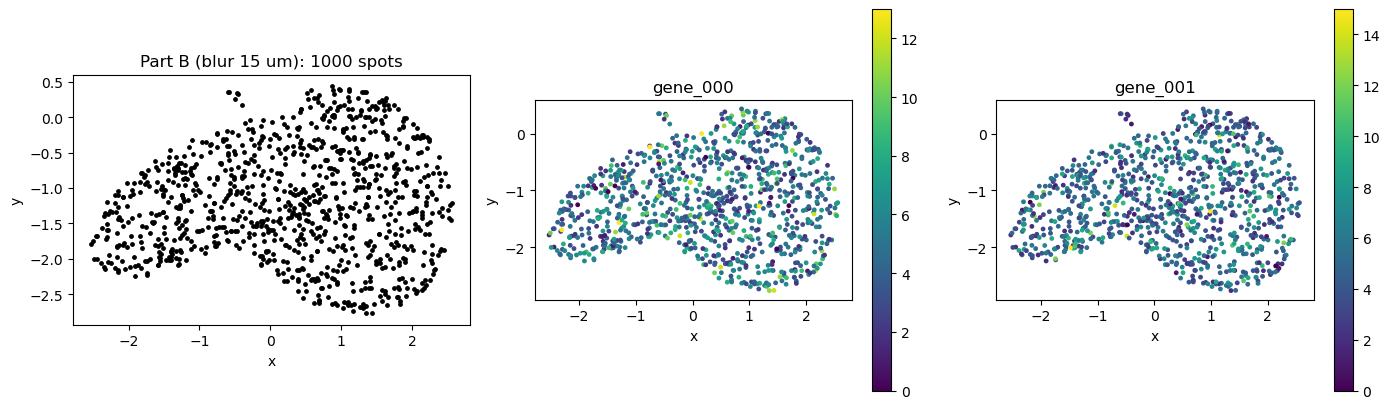

count mean 5.079, var 5.841, mean nearest-neighbor correlation 0.117


In [9]:
counts_b, coords_b = simulate(
    sigma=BLUR_AMPLITUDE, scale=TISSUE_WIDTH_UM,
    kernel={"type": "smooth", "distance": BLUR_SIGMA_UM},
)
spot_um = np.median(cKDTree(coords_b).query(coords_b, k=2)[0][:, 1]) * TISSUE_WIDTH_UM / 6.0
print(f"median nearest-spot spacing: {spot_um:.1f} um; blur bandwidth: {BLUR_SIGMA_UM} um")
plot_dataset(counts_b, coords_b, f"Part B (blur {BLUR_SIGMA_UM:g} um)")

## B.1 GASTON and MorphoGAM

In [10]:
iso_b, gaston_b = run_gaston(counts_b, coords_b, OUT_DIR / f"blur{BLUR_SIGMA_UM:g}um" / "gaston_runs")
xyt_b, fxs_b, morpho_b = run_morphogam(counts_b, coords_b, OUT_DIR / f"blur{BLUR_SIGMA_UM:g}um" / "morphogam")

Training on device: cuda


epoch: 0


Training on device: cuda
epoch: 0


Training on device: cuda
epoch: 0


Training on device: cuda
epoch: 0


...

Training on device: cuda
epoch: 0


Training on device: cuda
epoch: 0



best model: /weka/scratch/jhu/uchitra1/users/ajain71/isodepth-statistical-testing/notebooks/kidney_noise_outputs/blur15um/gaston_runs/rep16
Poisson regression for ALL cell types


GASTON native SVGs (nonzero slope, p < 0.1): 76 / 200


MorphoGAM SVGs (pv.t < 0.05): 51 / 200


## B.2 Learned coordinates

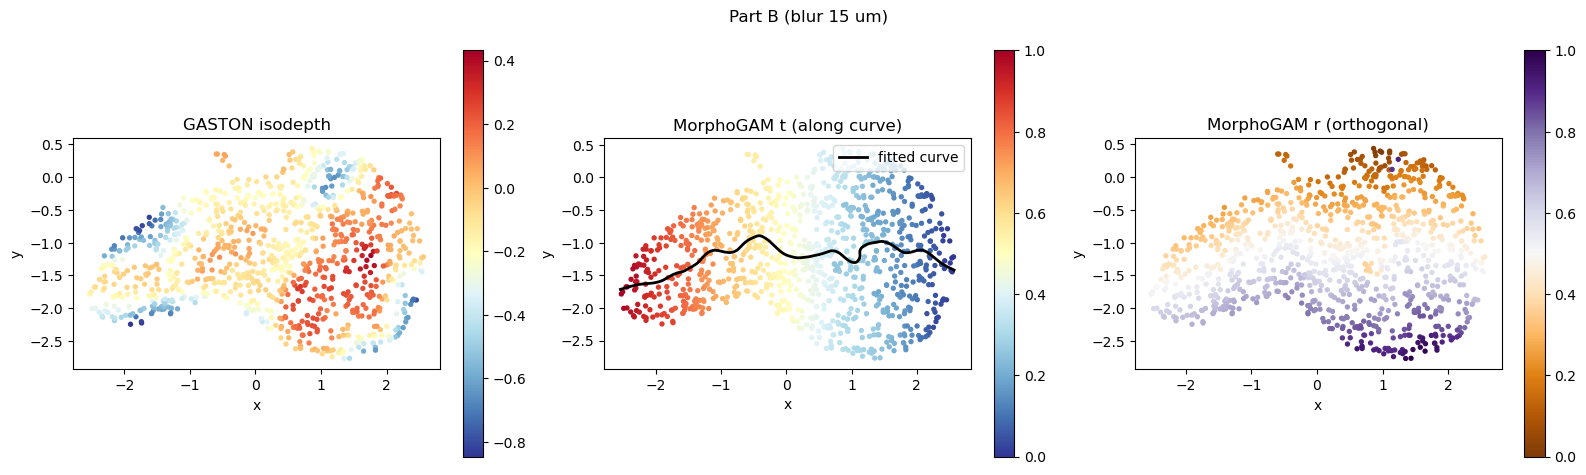

In [11]:
plot_coordinates(coords_b, iso_b, xyt_b, f"Part B (blur {BLUR_SIGMA_UM:g} um)")

## B.3 SVG counts

,dataset,method,rule,n_svgs,expected_if_calibrated,true_svgs
0,B: blur 15 um,GASTON,native: LLR p < 0.10,76,20.0,0
1,B: blur 15 um,GASTON,p < 0.05,55,10.0,0
2,B: blur 15 um,GASTON,BH q < 0.05,22,0.0,0
3,B: blur 15 um,MorphoGAM,pv.t < 0.05,51,10.0,0
4,B: blur 15 um,MorphoGAM,BH q < 0.05,18,0.0,0


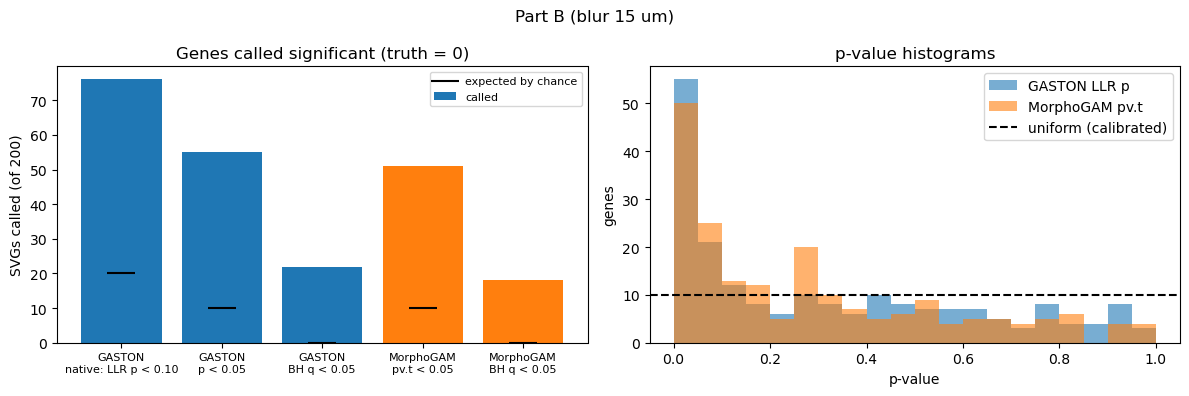

In [12]:
summary_b = svg_summary(gaston_b, morpho_b, f"B: blur {BLUR_SIGMA_UM:g} um")
display(summary_b)
plot_summary(summary_b, gaston_b, morpho_b, f"Part B (blur {BLUR_SIGMA_UM:g} um)")

## B.4 Top genes and overlap

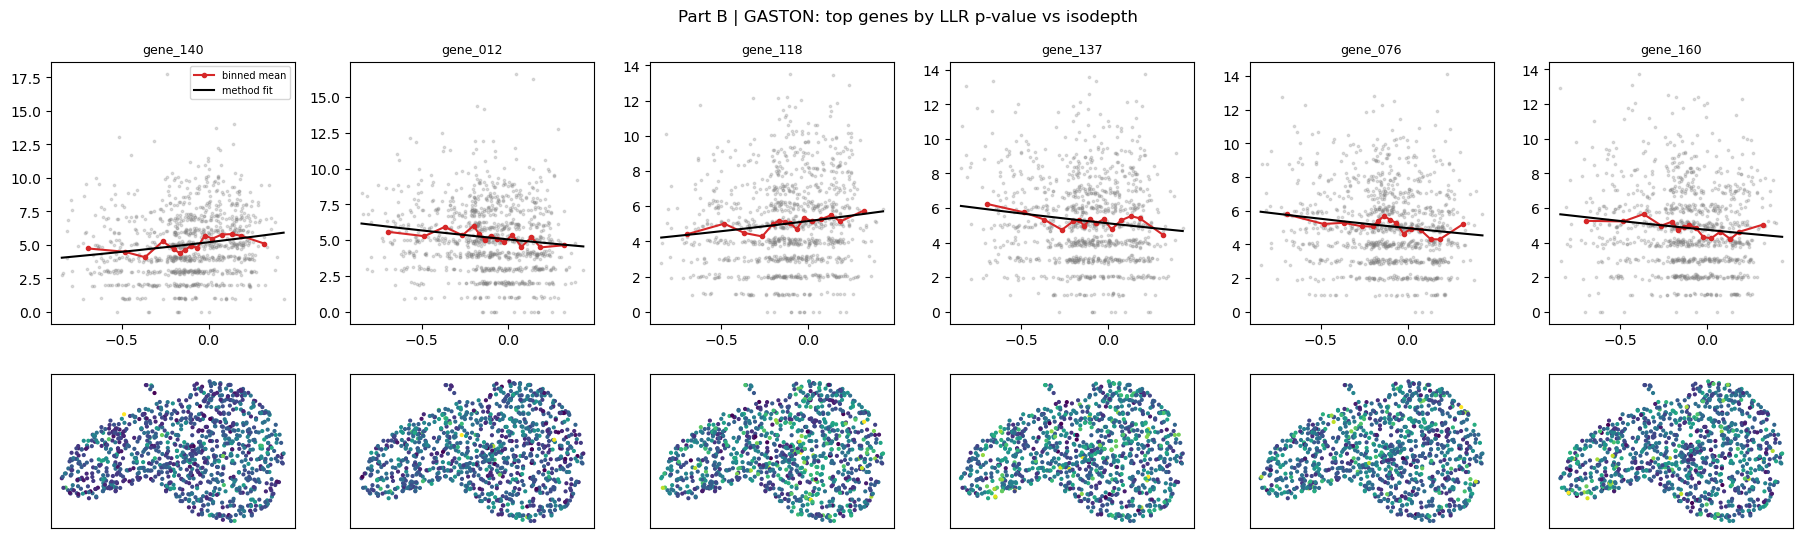

,gene,slope,intercept,pval,padj_bh
0,gene_140,0.297865,-5.275213,3.657693e-07,0.000073
1,gene_012,-0.235222,-5.303026,2.854026e-05,0.002854
2,gene_118,0.236749,-5.283578,5.131243e-05,0.003421
3,gene_137,-0.211741,-5.290528,1.562282e-04,0.007811
4,gene_076,-0.211098,-5.320175,2.042154e-04,0.008169
5,gene_160,-0.205411,-5.368829,4.240220e-04,0.014134


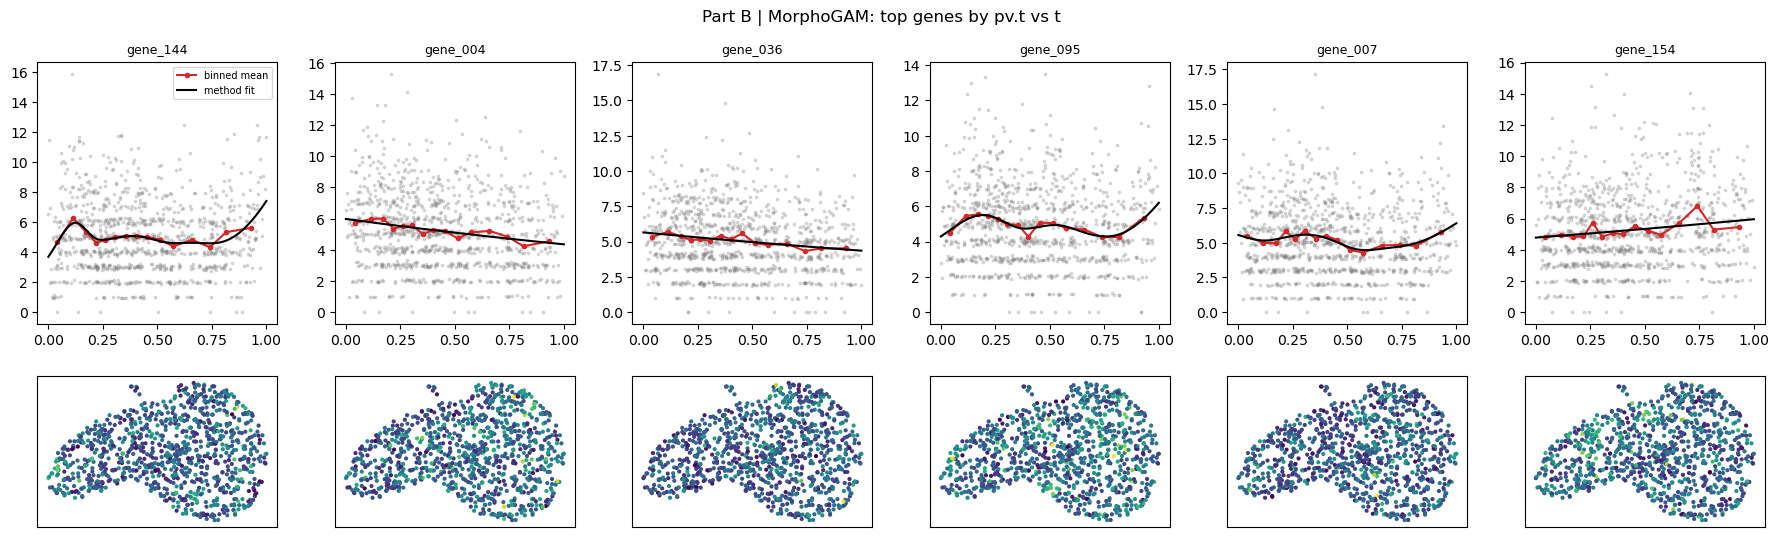

,gene,pv.t,padj_bh,peak.t,range.t
0,gene_144,-0.000002,-0.000454,0.206008,1.622926
1,gene_004,0.000000,0.000000,0.114877,1.049235
2,gene_036,0.000003,0.000224,0.084712,0.751038
3,gene_095,0.000035,0.001774,0.069309,0.622720
4,gene_007,0.000122,0.004110,0.075017,0.587405
5,gene_154,0.000123,0.004110,0.060826,0.572180


GASTON native SVGs: 76 | MorphoGAM SVGs: 51
Called by both: 23 -> ['gene_012', 'gene_013', 'gene_023', 'gene_036', 'gene_059', 'gene_061', 'gene_069', 'gene_075', 'gene_084', 'gene_086', 'gene_096', 'gene_100', 'gene_115', 'gene_118', 'gene_140', 'gene_144', 'gene_152', 'gene_154', 'gene_160', 'gene_169', 'gene_190', 'gene_191', 'gene_192']
Expected overlap if independent: 19.4


In [13]:
show_top_genes(counts_b, coords_b, iso_b, gaston_b, xyt_b, fxs_b, morpho_b, "Part B")
overlap(gaston_b, morpho_b)

# Summary: iid noise vs blurred noise

In [14]:
summary_all = pd.concat([summary_a, summary_b], ignore_index=True)
summary_all.to_csv(OUT_DIR / "svg_counts.csv", index=False)
display(summary_all.pivot_table(index=["method", "rule"], columns="dataset", values="n_svgs", sort=False))

dataset                         A: iid Poisson(5)  B: blur 15 um
method    rule                                                  
GASTON    native: LLR p < 0.10               20.0           76.0
          p < 0.05                           15.0           55.0
          BH q < 0.05                         0.0           22.0
MorphoGAM BH q < 0.05                         0.0           18.0
          pv.t < 0.05                         6.0           51.0